# 👻  **Taller 5 - Lógica difusa**

<img src="https://www.udistrital.edu.co/themes/custom/versh/images/default/preloader.png" align="left" width="192px" height="192px"/>
<img align="left" width="0" height="192px" hspace="10"/>

> Juan Felipe Rodríguez Galindo  - **COD. 20261595004**
<br></br>
[![Juan Felipe Rodriguez Galindo](https://img.shields.io/badge/Juferoga-github-br?style=flat-square)](https://github.com/Juferoga)
[![License](https://img.shields.io/badge/License-GPL_V.3-blue?style=flat-square)](https://www.gnu.org/licenses/gpl-3.0.html)


Inteligencia Computacional
Desarrollo del taller propuesto en la clase de Inteligencia Computacional.

## Paso 0. Entorno y datos

In [1]:
# ---- Preparación del entorno ----
import random, time, itertools
import numpy as np
import matplotlib.pyplot as plt

try:
    import skfuzzy as fuzz                       # scikit-fuzzy: se usa para COMPARAR con nuestro código
    from skfuzzy import control as ctrl
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-fuzzy"], check=False)
    import skfuzzy as fuzz
    from skfuzzy import control as ctrl

SEMILLA = 42
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s)
fijar_semilla()
print("NumPy", np.__version__, "| scikit-fuzzy", fuzz.__version__)

def verificar(nombre, ok, pista=""):
    """Punto de control: imprime [OK] o [REVISAR] con una pista."""
    print(("[OK]      " if ok else "[REVISAR] ") + nombre + ("" if ok else "  ->  " + pista))
    return ok


NumPy 2.5.4 | scikit-fuzzy 0.5.0


In [15]:
# ---- Funciones de pertenencia (mismos parámetros que en MATLAB) ----
def trimf(x, a, b, c):
    """Triangular [a b c]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if c == b else (c - x) / (c - b)
    return np.clip(np.minimum(izq, der), 0.0, 1.0)

def trapmf(x, a, b, c, d):
    """Trapezoidal [a b c d]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if d == c else (d - x) / (d - c)
    return np.clip(np.minimum(np.minimum(izq, 1.0), der), 0.0, 1.0)

def gaussmf(x, sigma, c):
    """Gaussiana [sigma c] (el orden de MATLAB: primero sigma, luego el centro)."""
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - c) ** 2) / (2.0 * sigma ** 2))

_MF = {"trimf": trimf, "trapmf": trapmf, "gaussmf": gaussmf}
def mf(tipo, params, x):
    return _MF[tipo](x, *params)


In [2]:
# ---- Fuzzy C-Means propio ----
def fcm_propio(X, c=3, m=2.0, iters=300, tol=1e-6, semilla=SEMILLA):
    """X: N x d. Devuelve centros (c x d), U (c x N), historial del objetivo J."""
    rng = np.random.default_rng(semilla)
    U = rng.random((c, len(X))); U /= U.sum(axis=0, keepdims=True)
    J = []
    for _ in range(iters):
        Um = U ** m
        centros = (Um @ X) / Um.sum(axis=1, keepdims=True)
        d = np.linalg.norm(X[None, :, :] - centros[:, None, :], axis=2) + 1e-12      # c x N
        J.append(float((Um * d ** 2).sum()))
        U_nueva = 1.0 / ((d[:, None, :] / d[None, :, :]) ** (2.0 / (m - 1))).sum(axis=1)
        if np.abs(U_nueva - U).max() < tol:
            U = U_nueva; break
        U = U_nueva
    return centros, U, J

def coeficiente_particion(U):
    """FPC = (1/N) * sum de U^2; vale 1/c con partición totalmente borrosa y 1 con partición nítida."""
    return float((U ** 2).sum() / U.shape[1])


In [3]:
# ---- Clasificador difuso con reglas extraídas de los datos (Wang-Mendel simplificado) ----
ETIQ = {2: ["bajo", "alto"], 3: ["bajo", "medio", "alto"],
        4: ["muy bajo", "bajo", "alto", "muy alto"], 5: ["muy bajo", "bajo", "medio", "alto", "muy alto"]}

def normalizar(X, mins, maxs):
    return np.clip((X - mins) / (maxs - mins + 1e-12), 0.0, 1.0)

def grados_pertenencia(Xn, n_mf):
    """Xn en [0,1]. Devuelve G de forma (N, F, n_mf) con n_mf triangulares uniformes."""
    centros = np.linspace(0, 1, n_mf)
    ancho = centros[1] - centros[0]
    G = np.stack([trimf(Xn, c - ancho, c, c + ancho) for c in centros], axis=2)
    return G

def extraer_reglas(Xn, y, n_mf):
    """Una regla por muestra (etiqueta dominante en cada característica); si dos muestras dan el mismo
    antecedente se conserva la de mayor grado. Devuelve (R: n_reglas x F, clases, grados)."""
    G = grados_pertenencia(Xn, n_mf)
    dom = G.argmax(axis=2)                                     # N x F
    grado = np.take_along_axis(G, dom[:, :, None], axis=2)[:, :, 0].prod(axis=1)
    mejores = {}
    for i in range(len(y)):
        clave = tuple(dom[i])
        if clave not in mejores or grado[i] > mejores[clave][1]:
            mejores[clave] = (int(y[i]), float(grado[i]))
    R = np.array(list(mejores.keys()))
    clases = np.array([v[0] for v in mejores.values()])
    grados = np.array([v[1] for v in mejores.values()])
    return R, clases, grados

def predecir_reglas(Xn, R, clases, n_mf, defecto=0):
    G = grados_pertenencia(Xn, n_mf)                           # N x F x n_mf
    F = G.shape[1]
    fuerza = G[:, np.arange(F)[None, :], R].prod(axis=2)        # N x n_reglas (t-norma = producto)
    pred = clases[fuerza.argmax(axis=1)]
    pred = np.where(fuerza.max(axis=1) > 0, pred, defecto)
    return pred, fuerza

def reglas_en_palabras(R, clases, grados, nombres_car, nombres_clase, n_mf, max_reglas=10):
    et = ETIQ[n_mf]
    orden = np.argsort(-grados)[:max_reglas]
    for k in orden:
        cond = " Y ".join(f"{nombres_car[f]} es {et[R[k, f]]}" for f in range(R.shape[1]))
        print(f"SI {cond} ENTONCES clase = {nombres_clase[clases[k]]}   (grado {grados[k]:.2f})")


In [4]:
# ---- Datos: conjuntos clásicos de la UCI incluidos en scikit-learn (no requieren internet) ----
def cargar_crudo(nombre="iris", test=0.3):
    from sklearn.datasets import load_iris, load_wine, load_breast_cancer
    from sklearn.model_selection import train_test_split
    d = {"iris": load_iris, "wine": load_wine, "breast_cancer": load_breast_cancer}[nombre]()
    Xtr, Xte, ytr, yte = train_test_split(d.data, d.target, test_size=test, stratify=d.target, random_state=SEMILLA)
    return dict(nombre=nombre, Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte,
                car=list(d.feature_names), clases=[str(t) for t in d.target_names])


In [5]:
from sklearn.metrics import accuracy_score, confusion_matrix, adjusted_rand_score
DATASET = "wine"            # "wine", "breast_cancer" o "iris"
d = cargar_crudo(DATASET)
print(DATASET, "| entrenamiento:", d["Xtr"].shape, "| prueba:", d["Xte"].shape, "| clases:", d["clases"])
print("Primeras características:", d["car"][:5])

wine | entrenamiento: (124, 13) | prueba: (54, 13) | clases: ['class_0', 'class_1', 'class_2']
Primeras características: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium']


## TODO 1. Selección de 4 características (solo con entrenamiento)
Use `SelectKBest(f_classif, k=4)` y ajústelo (`fit`) **únicamente** con `Xtr`/`ytr`. Guarde los índices en `idx`. ¿Por qué ajustar con todos los datos sería una fuga de información?

In [7]:
from sklearn.feature_selection import SelectKBest, f_classif
selector = SelectKBest(f_classif, k=4).fit(d["Xtr"],d["ytr"])
idx = selector.get_support(indices=True)
print("Características elegidas:", None if idx is None else [d["car"][i] for i in idx])

Características elegidas: ['alcohol', 'flavanoids', 'od280/od315_of_diluted_wines', 'proline']


In [8]:
# PUNTO DE CONTROL 1
verificar("idx tiene 4 índices distintos", idx is not None and len(set(idx)) == 4, "complete el TODO 1")
if idx is not None:
    from sklearn.feature_selection import f_classif as _f
    esperado = set(np.argsort(-np.nan_to_num(_f(d["Xtr"], d["ytr"])[0]))[:4])
    verificar("Coincide con los 4 mayores F calculados solo con entrenamiento", set(idx) == esperado, "ajuste con Xtr, no con todos los datos")

[OK]      idx tiene 4 índices distintos
[OK]      Coincide con los 4 mayores F calculados solo con entrenamiento


In [9]:
Xtr_s, Xte_s = d["Xtr"][:, idx], d["Xte"][:, idx]
mins, maxs = Xtr_s.min(0), Xtr_s.max(0)
Xtr, Xte = normalizar(Xtr_s, mins, maxs), normalizar(Xte_s, mins, maxs)
car = [d["car"][i] for i in idx]
print("Datos normalizados:", Xtr.shape, Xte.shape)

Datos normalizados: (124, 4) (54, 4)


## TODO 2. Una función de pertenencia nueva: sigmoidal
$$\mathrm{sigmf}(x;a,c)=\frac{1}{1+e^{-a(x-c)}}$$

con pendiente $a$ y punto de cruce $c$ (como `sigmf` en MATLAB). Impleméntela y verifique que vale 0.5 en $x=c$, que es creciente si $a>0$ y que coincide con `skfuzzy.sigmf`.

In [11]:
def sigmf(x, a, c):
    x = np.asarray(x, float)
    return 1.0 / (1.0 + np.exp(-a * (x-c)))

In [12]:
# PUNTO DE CONTROL 2
xs = np.linspace(-5, 5, 101)
try:
    y = np.asarray(sigmf(xs, 2.0, 1.0), dtype=float)
    verificar("sigmf(c; a, c) = 0.5", abs(float(sigmf(1.0, 2.0, 1.0)) - 0.5) < 1e-12, "revise la fórmula")
    verificar("Creciente para a > 0", bool(np.all(np.diff(y) > 0)), "")
    verificar("Coincide con scikit-fuzzy", np.allclose(y, fuzz.sigmf(xs, 1.0, 2.0)), "scikit-fuzzy usa (x, c, a)")
except Exception as e:
    print("[REVISAR] complete el TODO 2 ->", type(e).__name__)

[OK]      sigmf(c; a, c) = 0.5
[OK]      Creciente para a > 0
[OK]      Coincide con scikit-fuzzy


## TODO 3. Fuerza de las reglas con dos t-normas
Extraemos las reglas con `extraer_reglas` (ya implementada). Complete `fuerza_reglas` para calcular, para cada muestra y cada regla, el grado de disparo con la t-norma **mínimo** o **producto** sobre las 4 características.

In [18]:
N_MF = 3
R, clases_r, grados_r = extraer_reglas(Xtr, d["ytr"], N_MF)
print("Reglas extraídas:", len(R))

def fuerza_reglas(Xn, R, n_mf, tnorma="producto"):
    G = grados_pertenencia(Xn, n_mf)                    # N x F x n_mf
    F = G.shape[1]
    g = G[:, np.arange(F)[None, :], R]                  # N x n_reglas x F: grado de cada condición
    if tnorma == "producto":
        return g.prod(axis=2)
    return g.min(axis=2)

Reglas extraídas: 31


In [19]:
# PUNTO DE CONTROL 3
try:
    fp = fuerza_reglas(Xte, R, N_MF, "producto"); fm = fuerza_reglas(Xte, R, N_MF, "min")
    G0 = grados_pertenencia(Xte[:1], N_MF)[0]
    manual = [np.prod([G0[f, R[k, f]] for f in range(R.shape[1])]) for k in range(len(R))]
    verificar("Forma N x n_reglas", fp.shape == (len(Xte), len(R)), "")
    verificar("Producto coincide con el cálculo manual de la primera muestra", np.allclose(fp[0], manual), "")
    verificar("min >= producto (siempre, con grados en [0,1])", bool(np.all(fm >= fp - 1e-12)), "")
    for nombre, f in (("producto", fp), ("min", fm)):
        p = np.where(f.max(axis=1) > 0, clases_r[f.argmax(axis=1)], 0)
        print(f"Exactitud en prueba con t-norma {nombre}: {accuracy_score(d['yte'], p):.3f}")
except Exception as e:
    print("[REVISAR] complete el TODO 3 ->", type(e).__name__)

[OK]      Forma N x n_reglas
[OK]      Producto coincide con el cálculo manual de la primera muestra
[OK]      min >= producto (siempre, con grados en [0,1])
Exactitud en prueba con t-norma producto: 0.926
Exactitud en prueba con t-norma min: 0.926


## TODO 4. Evaluación e interpretación de errores
Con la t-norma producto: calcule la exactitud, la matriz de confusión y **el par de clases más confundido** (real → predicha, fuera de la diagonal). Imprima también las 3 reglas de mayor grado en palabras.

In [33]:
f = fuerza_reglas(Xte, R, N_MF, "producto") if idx is not None and fuerza_reglas(Xte, R, N_MF) is not None else None

pred = clases_r[f.argmax(axis=1)]; 
pred = np.where(f.max(axis=1) > 0, pred, 0)

exactitud = accuracy_score(d["yte"],pred); 

cm = confusion_matrix(d["yte"],pred); 

fuera=cm.copy()
np.fill_diagonal(fuera,0)

par = tuple(int(v) for v in np.unravel_index(fuera.argmax(), fuera.shape)) 
reglas_en_palabras(R, clases_r, grados_r, car, d["clases"], N_MF, max_reglas=5)
print("Exactitud:", exactitud); print(cm); print("Par más confundido (real, predicha):", par)

SI alcohol es medio Y flavanoids es medio Y od280/od315_of_diluted_wines es medio Y proline es medio ENTONCES clase = class_1   (grado 0.60)
SI alcohol es bajo Y flavanoids es medio Y od280/od315_of_diluted_wines es medio Y proline es bajo ENTONCES clase = class_1   (grado 0.58)
SI alcohol es medio Y flavanoids es medio Y od280/od315_of_diluted_wines es medio Y proline es bajo ENTONCES clase = class_1   (grado 0.54)
SI alcohol es medio Y flavanoids es bajo Y od280/od315_of_diluted_wines es medio Y proline es medio ENTONCES clase = class_2   (grado 0.52)
SI alcohol es alto Y flavanoids es alto Y od280/od315_of_diluted_wines es medio Y proline es medio ENTONCES clase = class_0   (grado 0.49)
Exactitud: 0.9259259259259259
[[17  1  0]
 [ 1 18  2]
 [ 0  0 15]]
Par más confundido (real, predicha): (1, 2)


In [34]:
# PUNTO DE CONTROL 4
ok = pred is not None and cm is not None
verificar("La matriz de confusión suma el número de muestras de prueba", ok and cm.sum() == len(d["yte"]), "complete el TODO 4")
verificar("Exactitud en prueba > 80 %", ok and exactitud > 0.80, "revise características y normalización")
verificar("El par más confundido tiene dos clases distintas", ok and par is not None and par[0] != par[1], "")

[OK]      La matriz de confusión suma el número de muestras de prueba
[OK]      Exactitud en prueba > 80 %
[OK]      El par más confundido tiene dos clases distintas


True

## TODO 5. Experimento: etiquetas, reglas, exactitud y árbol
Para `n_mf` en 2, 3 y 4 calcule el número de reglas y la exactitud de prueba del clasificador difuso, y compárela con un `DecisionTreeClassifier` con el mismo número de hojas (`max_leaf_nodes`). **Antes de ejecutar, escriba su predicción en una celda de texto.** Luego redacte 5 líneas con su conclusión.

In [35]:
from sklearn.tree import DecisionTreeClassifier


In [45]:
resultados = []     # lista de tuplas (n_mf, n_reglas, exactitud_difusa, exactitud_arbol)
for n in (2, 3, 4):
    Rn, cn, gn = extraer_reglas(Xtr, d["ytr"], n)
    p, _ = predecir_reglas(Xte, Rn, cn, n)
    arbol = DecisionTreeClassifier(max_leaf_nodes=len(Rn), random_state=SEMILLA).fit(Xtr_s, d['ytr'])
    resultados.append((n, len(Rn), accuracy_score(d['yte'], p), accuracy_score(d['yte'], arbol.predict(Xte_s))))
print(f"{'n_mf':>5} {'reglas':>7} {'difusa':>8} {'árbol':>8}")
for n, nr, a1, a2 in resultados:
    print(f"{n:>5} {nr:>7} {a1:>8.3f} {a2:>8.3f}")

      n_mf  reglas   difusa    árbol
    2      10    0.759    0.870
    3      31    0.926    0.870
    4      43    0.889    0.870


In [42]:
# PUNTO DE CONTROL 5
verificar("Se evaluaron 3 valores de n_mf", len(resultados) == 3, "complete el TODO 5")
if len(resultados) == 3:
    rs = [r[1] for r in resultados]
    verificar("El número de reglas no decrece con n_mf", all(b >= a for a, b in zip(rs, rs[1:])), "")
    verificar("Ningún número de reglas supera n_mf^4", all(r[1] <= r[0] ** 4 for r in resultados), "")

[OK]      Se evaluaron 3 valores de n_mf
[OK]      El número de reglas no decrece con n_mf
[OK]      Ningún número de reglas supera n_mf^4


**Redacte aquí (5 líneas):** 
- ¿Qué `n_mf` elegiría?
Elegiría 3.
- ¿Cómo cambia el número de reglas?
Primero crece y después decrece, se sobreajusta o sobreentrena.
- ¿El árbol con las mismas hojas es mejor o peor?
Igual siempre 0.87.
- ¿Qué diría de la interpretabilidad?
Es mejor en en el conjunto difuso porque uno puede extraer las normas de allí con mayor entendimiento.
- ¿Qué tan fiables son diferencias de un par de puntos con esta muestra de prueba?
La prueba tiene 54 vinos, una muestra equivale a 1.85 puntos. 92.6 contra 88.9 son uno o dos vinos de diferencia, con otra segmentación puede llegar a confundir o dar más falsos positivos. 


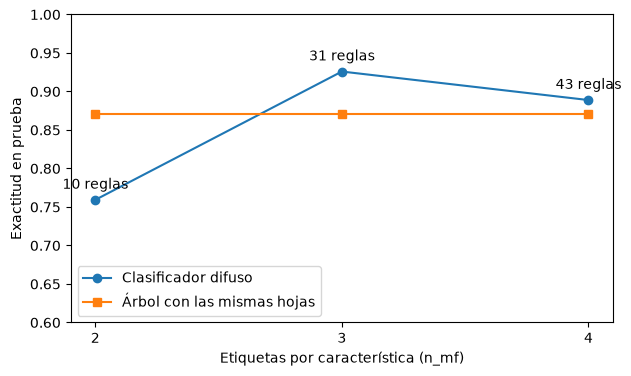

In [47]:
import os
ns = [r[0] for r in resultados]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, [r[2] for r in resultados], marker="o", label="Clasificador difuso")
ax.plot(ns, [r[3] for r in resultados], marker="s", label="Árbol con las mismas hojas")
for n, nr, a1, _ in resultados:
    ax.annotate(f"{nr} reglas", (n, a1), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set(xlabel="Etiquetas por característica (n_mf)", ylabel="Exactitud en prueba", xticks=ns, ylim=(0.6, 1.0))
ax.legend()
os.makedirs("figuras", exist_ok=True)
plt.savefig("figuras/exactitud_nmf.png", dpi=150, bbox_inches="tight")
plt.show()

## TODO 6. Fuzzy C-Means y exportación para MATLAB
Agrupe **todas** las muestras (sin etiquetas) en 3 grupos con `fcm_propio`, calcule el ARI frente a las clases reales y guarde los CSV que usará en MATLAB. Complete el cálculo de `ari`.

In [48]:
X_all = np.vstack([Xtr_s, Xte_s]); y_all = np.concatenate([d["ytr"], d["yte"]])
Xa = normalizar(X_all, X_all.min(0), X_all.max(0))
centros, U, J = fcm_propio(Xa, c=3, m=2.0)
grupo = U.argmax(axis=0)
ari = adjusted_rand_score(y_all, grupo)
print("ARI FCM:", ari)

ARI FCM: 0.794382757910199


In [50]:
# PUNTO DE CONTROL 6
verificar("Los grados de cada muestra suman 1", np.allclose(U.sum(axis=0), 1), "")
verificar("ARI calculado y mayor que 0.3", ari is not None and ari > 0.3, "complete el TODO 6")

# Exportación para MATLAB (Fuzzy Logic Designer, genfis, fcm): una fila por muestra, última columna = clase
import csv, os
def guardar(nombre, X, y):
    with open(nombre, "w", newline="") as fh:
        w = csv.writer(fh); w.writerow([c.replace(" ", "_") for c in car] + ["clase"])
        for fila, cl in zip(X, y):
            w.writerow([f"{v:.6f}" for v in fila] + [int(cl)])
guardar(f"{DATASET}_4car_train.csv", Xtr_s, d["ytr"]); guardar(f"{DATASET}_4car_test.csv", Xte_s, d["yte"])
print("Archivos creados:", [f for f in os.listdir(".") if f.endswith(".csv")])
try:
    from google.colab import files
    files.download(f"{DATASET}_4car_train.csv"); files.download(f"{DATASET}_4car_test.csv")
except Exception:
    print("(Fuera de Colab: los archivos quedan en la carpeta de trabajo.)")

[OK]      Los grados de cada muestra suman 1
[OK]      ARI calculado y mayor que 0.3
Archivos creados: ['wine_4car_train.csv', 'wine_4car_test.csv']
(Fuera de Colab: los archivos quedan en la carpeta de trabajo.)
